In [2]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

Epoch: 0 | Loss: 1.76081, Acc: 24.12% | Test Loss: 1.38527, Test Acc: 28.50%
Epoch: 10 | Loss: 0.57927, Acc: 92.75% | Test Loss: 0.49055, Test Acc: 94.50%
Epoch: 20 | Loss: 0.20258, Acc: 99.00% | Test Loss: 0.17154, Test Acc: 99.00%
Epoch: 30 | Loss: 0.09663, Acc: 99.12% | Test Loss: 0.08405, Test Acc: 99.50%
Epoch: 40 | Loss: 0.06547, Acc: 99.12% | Test Loss: 0.05583, Test Acc: 99.50%
Epoch: 50 | Loss: 0.05185, Acc: 99.12% | Test Loss: 0.04292, Test Acc: 99.50%
Epoch: 60 | Loss: 0.04446, Acc: 99.25% | Test Loss: 0.03575, Test Acc: 99.50%
Epoch: 70 | Loss: 0.03992, Acc: 99.25% | Test Loss: 0.03123, Test Acc: 99.50%
Epoch: 80 | Loss: 0.03687, Acc: 99.25% | Test Loss: 0.02813, Test Acc: 99.50%
Epoch: 90 | Loss: 0.03470, Acc: 99.25% | Test Loss: 0.02590, Test Acc: 99.50%


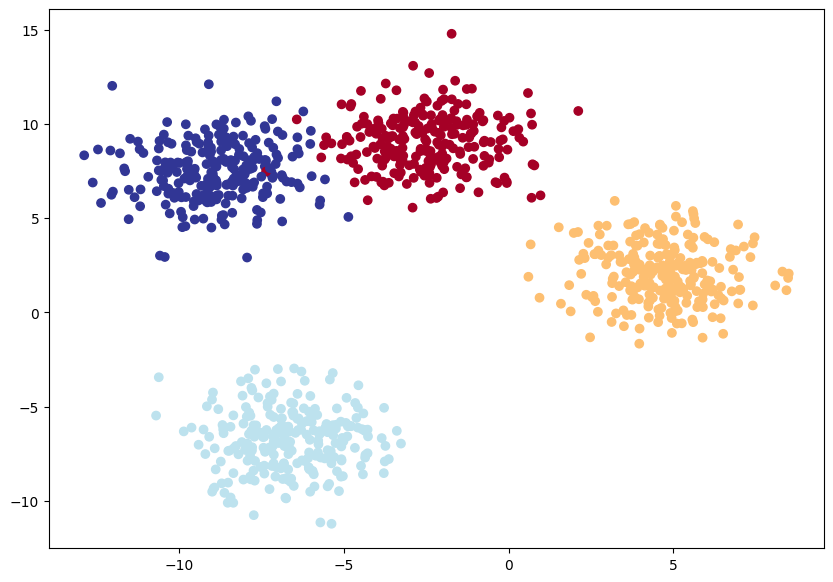

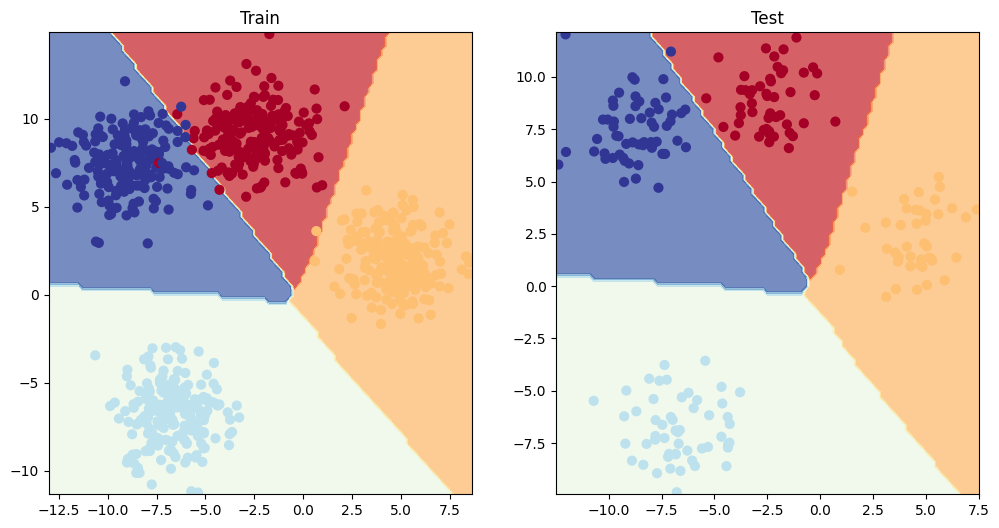

In [3]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
import torch.nn as nn
from helper_functions import plot_decision_boundary
NUM_FEATURES = 2
NUM_CLASSES = 4
RANDOM_SEED = 42

device = "cuda" if torch.cuda.is_available() else "cpu"
X_blob , Y_blob = make_blobs(n_samples=1000,cluster_std=1.5,n_features=2,centers=NUM_CLASSES,random_state=RANDOM_SEED)


X_blob = torch.from_numpy(X_blob).type(torch.float)
Y_blob = torch.from_numpy(Y_blob).type(torch.LongTensor)


X_blob_train , X_blob_test , Y_blob_train , Y_blob_test = train_test_split(X_blob,Y_blob,test_size=0.2,random_state=RANDOM_SEED)

plt.figure(figsize=(10,7))
plt.scatter(X_blob[:,0],X_blob[:,1],c=Y_blob,cmap=plt.cm.RdYlBu)


def accuracy_fn(Values,True_Values):
    correct = torch.eq(True_Values,Values).sum().item()
    acc = (correct / len(Values) * 100)
    return acc

class model(nn.Module):
    def __init__(self, input_features , output_features , hidden_layers = 8):
        super().__init__()
        self.linear_stack = nn.Sequential(
            nn.Linear(in_features=input_features,out_features=hidden_layers),
            nn.ReLU(),
            nn.Linear(in_features=hidden_layers,out_features=hidden_layers),
            nn.ReLU(),
            nn.Linear(in_features=hidden_layers,out_features=output_features)
        )

    def forward(self,x):
        return self.linear_stack(x)


Blob_model = model(input_features=NUM_FEATURES,output_features=NUM_CLASSES,hidden_layers=8).to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(params=Blob_model.parameters(),lr=0.1)


X_blob_train , X_blob_test , Y_blob_train , Y_blob_test = X_blob_train.to(device) , X_blob_test.to(device) , Y_blob_train.to(device) , Y_blob_test.to(device)

torch.manual_seed(42)

epochs = 100

for epoch in range(epochs):
    Blob_model.train()

    y_logits = Blob_model(X_blob_train)
    y_preds = torch.softmax(y_logits,dim=1).argmax(dim=1)

    loss = loss_fn(y_logits,Y_blob_train)
    accuracy = accuracy_fn(True_Values=Y_blob_train,Values=y_preds)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    Blob_model.eval()
    with torch.inference_mode():
        test_logits = Blob_model(X_blob_test)
        y_test_preds = torch.softmax(test_logits,dim=1).argmax(dim=1)

        test_loss = loss_fn(test_logits,Y_blob_test)
        test_accuracy = accuracy_fn(True_Values=Y_blob_test,Values=y_test_preds)

    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {accuracy:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_accuracy:.2f}%")


plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(Blob_model,X_blob_train,Y_blob_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(Blob_model,X_blob_test,Y_blob_test)
plt.show()